(ortools-nonogram)=
# 解数织：把每个数字的起始位置设为整数变量

## 本章的内容

在 [PySAT 一章](pysat-nonogram)中，我们把所有可能的涂法都写成 CNF 之后交给求解器，而本章改用 CP-SAT 求解同一个问题，做法与 PySAT 一章完全不同。

- CP-SAT 能处理整数变量，因此可以把“每个数字的起始位置”直接作为变量
- 由起始位置确定的涂法，用布尔变量的 AND 与 OR 连接起来即可
- 即使是 45×60 的大型题目，也能在十几秒内求出解来

与 PySAT 一章的差别不在题目，而在变量的选取。

:::{seealso}
[用 PySAT 解数织游戏](pysat-nonogram)
:::

In [1]:
from ortools.sat.python import cp_model
from helper.ortools import get_all_solutions

## 用起始位置表示一行的提示数字

设一行的提示为 `[2, 1]`、宽度为 5 格。这时数字 2 从第 0 格到第 2 格中的某一格开始，数字 1 则从它后面开始，两者之间至少留出一格。

`place_numbers()` 把每个数字的起始位置设为整数变量，然后加入下面的两条约束。起点是唯一需要确定的量：起点确定之后，每个数字的长度固定，涂哪些格也随之固定，因此一个整数变量就代替了整行的一组布尔变量。

- `n2 > n1 + 长度`：相邻的两个数字不重叠，中间至少空出一格
- 最后一个数字的起始位置不得超过 `width - 长度`，即不能超出行的右端

In [2]:
import string


def place_numbers(model, numbers, width, prefix=""):
    """为每个数字创建表示开始位置的整数变量，并约束它们不重叠"""
    locations = [model.new_int_var(0, width - 1, f"{prefix}{name}")
                 for _, name in zip(numbers, string.ascii_uppercase)]
    # 相邻的数字之间至少空 1 格
    for n1, n2, length in zip(locations[:-1], locations[1:], numbers):
        model.add(n2 > n1 + length)
    # 最后一个数字不能超出右端
    model.add(locations[-1] <= width - numbers[-1])
    return locations


def show_all_locations(numbers, width):
    """显示开始位置的所有组合"""
    model = cp_model.CpModel()
    place_numbers(model, numbers, width)
    return get_all_solutions(model)

下面给出宽度为 5 格、提示为 `[2, 1]` 时的全部解。

In [3]:
show_all_locations([2, 1], 5)

[{'A': 0, 'B': 3}, {'A': 0, 'B': 4}, {'A': 1, 'B': 4}]

下面是宽度为 10 格、提示为 `[3, 2, 2]` 的情形。

In [4]:
show_all_locations([3, 2, 2], 10)

[{'A': 0, 'B': 4, 'C': 7},
 {'A': 0, 'B': 4, 'C': 8},
 {'A': 0, 'B': 5, 'C': 8},
 {'A': 1, 'B': 5, 'C': 8}]

## 由起始位置涂格

起始位置一经确定，要涂的格也就随之确定，因此剩下的工作就只是把“起始位置”与“每一格的状态”这两者连接起来。

```{mermaid}
graph LR
subgraph C_fill["Targets"]
direction LR
c0[1]
c1[1]
c2[0]
c3[1]
c4[0]

c0 ~~~ c1
c1 ~~~ c2
c2 ~~~ c3
c3 ~~~ c4
end

subgraph A_fill["A Fill"]
direction LR
a0[1]
a1[1]
a2[0]
a3[0]
a4[0]
a0 ~~~ a1
a1 ~~~ a2
a2 ~~~ a3
a3 ~~~ a4
end

subgraph B_fill["B Fill"]
direction LR
b0[0]
b1[0]
b2[0]
b3[1]
b4[0]
b0 ~~~ b1
b1 ~~~ b2
b2 ~~~ b3
b3 ~~~ b4
end

A["A=0 (n=2)"]
B["B=3 (n=1)"]
A --> A_fill
B --> B_fill
A_fill --> C_fill
B_fill --> C_fill
```

对每个数字分别做出各自的涂法，即 `A Fill` 与 `B Fill`，再逐格取 OR，得到的就是 `Targets`，也就是这一行最终的涂法。每一块的涂法在自身范围内是确定的，重叠与间隔由 OR 与后面的约束处理。

在 CP-SAT 中需要表达“起始位置为 `i` 时这一格涂、否则不涂”这样的条件分支，而比较式又不能直接用作约束的前提。因此先准备一个与 `n == i` 等价的布尔变量 `b`，前提只接受布尔变量及其否定，再用 `b` 来控制分支。

```python
model.add(n == i).only_enforce_if(b)     # b 为真时要求 n == i
model.add(n != i).only_enforce_if(~b)    # b 为假时要求 n != i
```

在此基础上，再把每一格的状态 `targets[i]` 与各数字的涂法 `fills[i, j]` 连接起来。

- `targets[i]` 为真：第 `i` 格要涂，至于涂它的是哪个数字并不限定，因此要求至少有一个为真
- `targets[i]` 为假：第 `i` 格不涂，因此要求全部为假

In [5]:
def fill_pattern(model, numbers, targets, prefix=""):
    """在 targets（格子变量）上放置 numbers 的约束"""
    width = len(targets)
    count = len(numbers)
    locations = place_numbers(model, numbers, width, prefix)

    # fills[i, j] : 格子 i 是否由数字 j 涂上
    fills = {}
    for i in range(width):
        for j in range(count):
            fills[i, j] = model.new_bool_var(f'{locations[j].name}_{i}')

    for j, n in enumerate(locations):
        for i in range(width - numbers[j] + 1):
            # b 是表示“数字 j 的开始位置为 i”的布尔变量
            b = model.new_bool_var(f'{n.name}_{i}')
            model.add(n == i).only_enforce_if(b)
            model.add(n != i).only_enforce_if(~b)

            # b 成立时，从格子 i 开始涂 numbers[j] 格
            tmp = [fills[x, j] if i <= x < i + numbers[j] else ~fills[x, j]
                   for x in range(width)]
            model.add_bool_and(tmp).only_enforce_if(b)

    # 把格子的状态和每个数字的涂法连起来
    for i, t in enumerate(targets):
        bools = [fills[i, j] for j in range(count)]
        model.add_bool_or(bools).only_enforce_if(t)          # 涂的话，是某个数字
        model.add_bool_and([~v for v in bools]).only_enforce_if(~t)  # 不涂的话，全部为假


def show_all_fills(numbers, width):
    """显示一行涂法的所有解"""
    model = cp_model.CpModel()
    targets = [model.new_bool_var(f"{i}") for i in range(width)]
    fill_pattern(model, numbers, targets)
    for sol in get_all_solutions(model):
        print([sol[t.name] for t in targets])

下面是宽度为 5 格、提示为 `[2, 1]` 时的涂法。

In [6]:
show_all_fills([2, 1], 5)

[1, 1, 0, 0, 1]
[1, 1, 0, 1, 0]
[0, 1, 1, 0, 1]


下面是宽度为 10 格、提示为 `[3, 2, 2]` 时的涂法。

In [7]:
show_all_fills([3, 2, 2], 10)

[1, 1, 1, 0, 1, 1, 0, 0, 1, 1]
[1, 1, 1, 0, 0, 1, 1, 0, 1, 1]
[1, 1, 1, 0, 1, 1, 0, 1, 1, 0]
[0, 1, 1, 1, 0, 1, 1, 0, 1, 1]


## 求解数织

为每一格建立变量，再从行和列两个方向分别应用 `fill_pattern()`。行与列的约束写法相同，只是遍历的方向不同。由于两个方向共用同一批格变量，行与列的条件会同时得到满足。两个方向各自算出的候选，由这些变量自动取交集。

In [8]:
def solve_nonogram(rows, cols):
    """由行、列的提示求出涂法"""
    model = cp_model.CpModel()
    width = len(cols)
    height = len(rows)

    # 每个格子的布尔变量
    cells = [[model.new_bool_var(f"T_{r}_{c}") for c in range(width)]
             for r in range(height)]

    # 行的条件
    for r, numbers in enumerate(rows):
        fill_pattern(model, numbers, cells[r], f"R{r}")

    # 列的条件
    for c, numbers in enumerate(cols):
        line = [cells[i][c] for i in range(height)]
        fill_pattern(model, numbers, line, f"C{c}")

    solver = cp_model.CpSolver()
    if solver.solve(model) not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        raise ValueError("没有找到解")

    return [[solver.value(cell) for cell in row] for row in cells]

## 45×60 的题目

下面解一道大型题目，共 45 行、60 列。规模变大之后，变量与约束按比例增加。解题方式不变，读入方式与前面的例题相同。

In [9]:
%%time
import json

with open("data/nonogram03.json") as f:
    puzzle = json.load(f)

result = solve_nonogram(**puzzle)

CPU times: total: 5.31 s
Wall time: 5.46 s


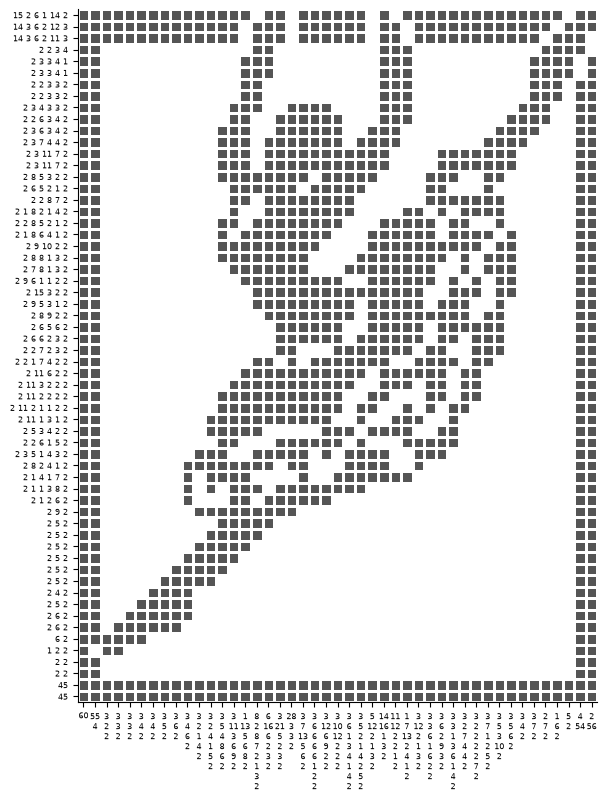

In [10]:
from helper.plot import plot_nonogram_board

plot_nonogram_board(puzzle, result, font_size=6);

## 验算

最后再确认一次，得到的涂法是否与提示一致。做法是数出每一行、每一列中连续黑格的段长，再与提示逐一比较，这一步与求解无关，只检查答案。

In [11]:
def runs(line):
    """按顺序取出连续 1 的长度"""
    result, n = [], 0
    for x in line:
        if x:
            n += 1
        elif n:
            result.append(n)
            n = 0
    if n:
        result.append(n)
    return result


def check_nonogram(rows, cols, solution):
    ok_rows = [runs(solution[i]) for i in range(len(rows))] == [list(r) for r in rows]
    ok_cols = [runs([solution[i][j] for i in range(len(rows))]) for j in range(len(cols))] == [list(c) for c in cols]
    return ok_rows and ok_cols


print(check_nonogram(puzzle["rows"], puzzle["cols"], result))

True


## 小结

- CP-SAT 可以把起始位置做成整数变量，不必像 PySAT 一章那样把候选的涂法全部写成 CNF
- 起始位置的约束只有两条：`n2 > n1 + 长度`，另一条是不超出行的右端
- 比较式不能直接作为约束的前提，因此要建立一个表示 `n == i` 的布尔变量 `b`，再用 `only_enforce_if()` 分支
- 行与列共用同一批格变量，两个方向的条件就会同时成立
- 45×60 的题目用这个方法也能在十几秒内解出